# Global land cover from coordinates

Train a [Wrap encoder](https://github.com/MarcCoru/locationencoder/blob/main/locationencoder/pe/wrap.py) and MLP on the [CGLC-MODIS-LCZ map](https://zenodo.org/records/7670653), then visualize and classify the bottleneck embeddings.

[![Open in Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/neuralearthfields/neuralearthfields-starter/blob/main/starter.ipynb)

## Setup

Locally, run `uv sync` and `uv run jupyter lab`. In Colab, select a GPU runtime and run the installation cell below; restart if prompted.

In [1]:
import os
import subprocess
import sys
import tomllib
from pathlib import Path

if "google.colab" in sys.modules:
    repo = Path("/content/neuralearthfields-starter")
    if not repo.exists():
        subprocess.run(
            [
                "git",
                "clone",
                "--depth",
                "1",
                "https://github.com/neuralearthfields/neuralearthfields-starter.git",
                str(repo),
            ],
            check=True,
        )
    os.chdir(repo)
    sys.path.insert(0, str(repo))
    dependencies = tomllib.loads(Path("pyproject.toml").read_text())["project"][
        "dependencies"
    ]
    subprocess.run([sys.executable, "-m", "pip", "install", *dependencies], check=True)

## Configuration

The default architecture is `Wrap (4) → 256 → 128 → 256 → 31`. `hidden_dim` controls the middle bottleneck and exported embedding bands.

In [2]:
from pathlib import Path

import lightning as L
import numpy as np
import rasterio
import torch
from huggingface_hub import hf_hub_download
from lightning.pytorch.loggers import CSVLogger
from rasterio.windows import Window
from torch import nn
from torch.utils.data import DataLoader, TensorDataset
from torchmetrics import MetricCollection
from torchmetrics.classification import (
    MulticlassAccuracy,
    MulticlassF1Score,
    MulticlassJaccardIndex,
)

from plot import (
    pca_rgb,
    plot_comparison,
    plot_land_cover,
    plot_metrics,
    preview_grid,
    read_palette,
)

source = Path("data/CGLC-MODIS-LCZ-100m.cog.tif")
output = Path("outputs")
input_dim = 256
hidden_dim = 128
output_dim = input_dim
class_codes = np.r_[1:17, 18:22, 51:62].astype("uint8")
num_classes = len(class_codes)
batch_size = 4096
train_samples = 2**20
train_steps = 5000
probe_steps = 1000
test_batches = 16
eval_every = 250
learning_rate = 1e-3
nearby_fraction = 0.5
radius_pixels = 5
preview_height = 768
seed = 0
source.parent.mkdir(exist_ok=True)
output.mkdir(exist_ok=True)
device = torch.device(
    "cuda"
    if torch.cuda.is_available()
    else "mps"
    if torch.backends.mps.is_available()
    else "cpu"
)
torch.manual_seed(seed)
torch.set_num_threads(4)
torch.set_float32_matmul_precision("high")
print(device)

mps


## Land cover

Download the full COG and plot it at four scales. Include land and lakes (21); exclude ocean (17) and invalid labels.

400,752 × 153,622 pixels; (0.0008983152841194946, 0.0008983152841194824); (512, 512) tiles


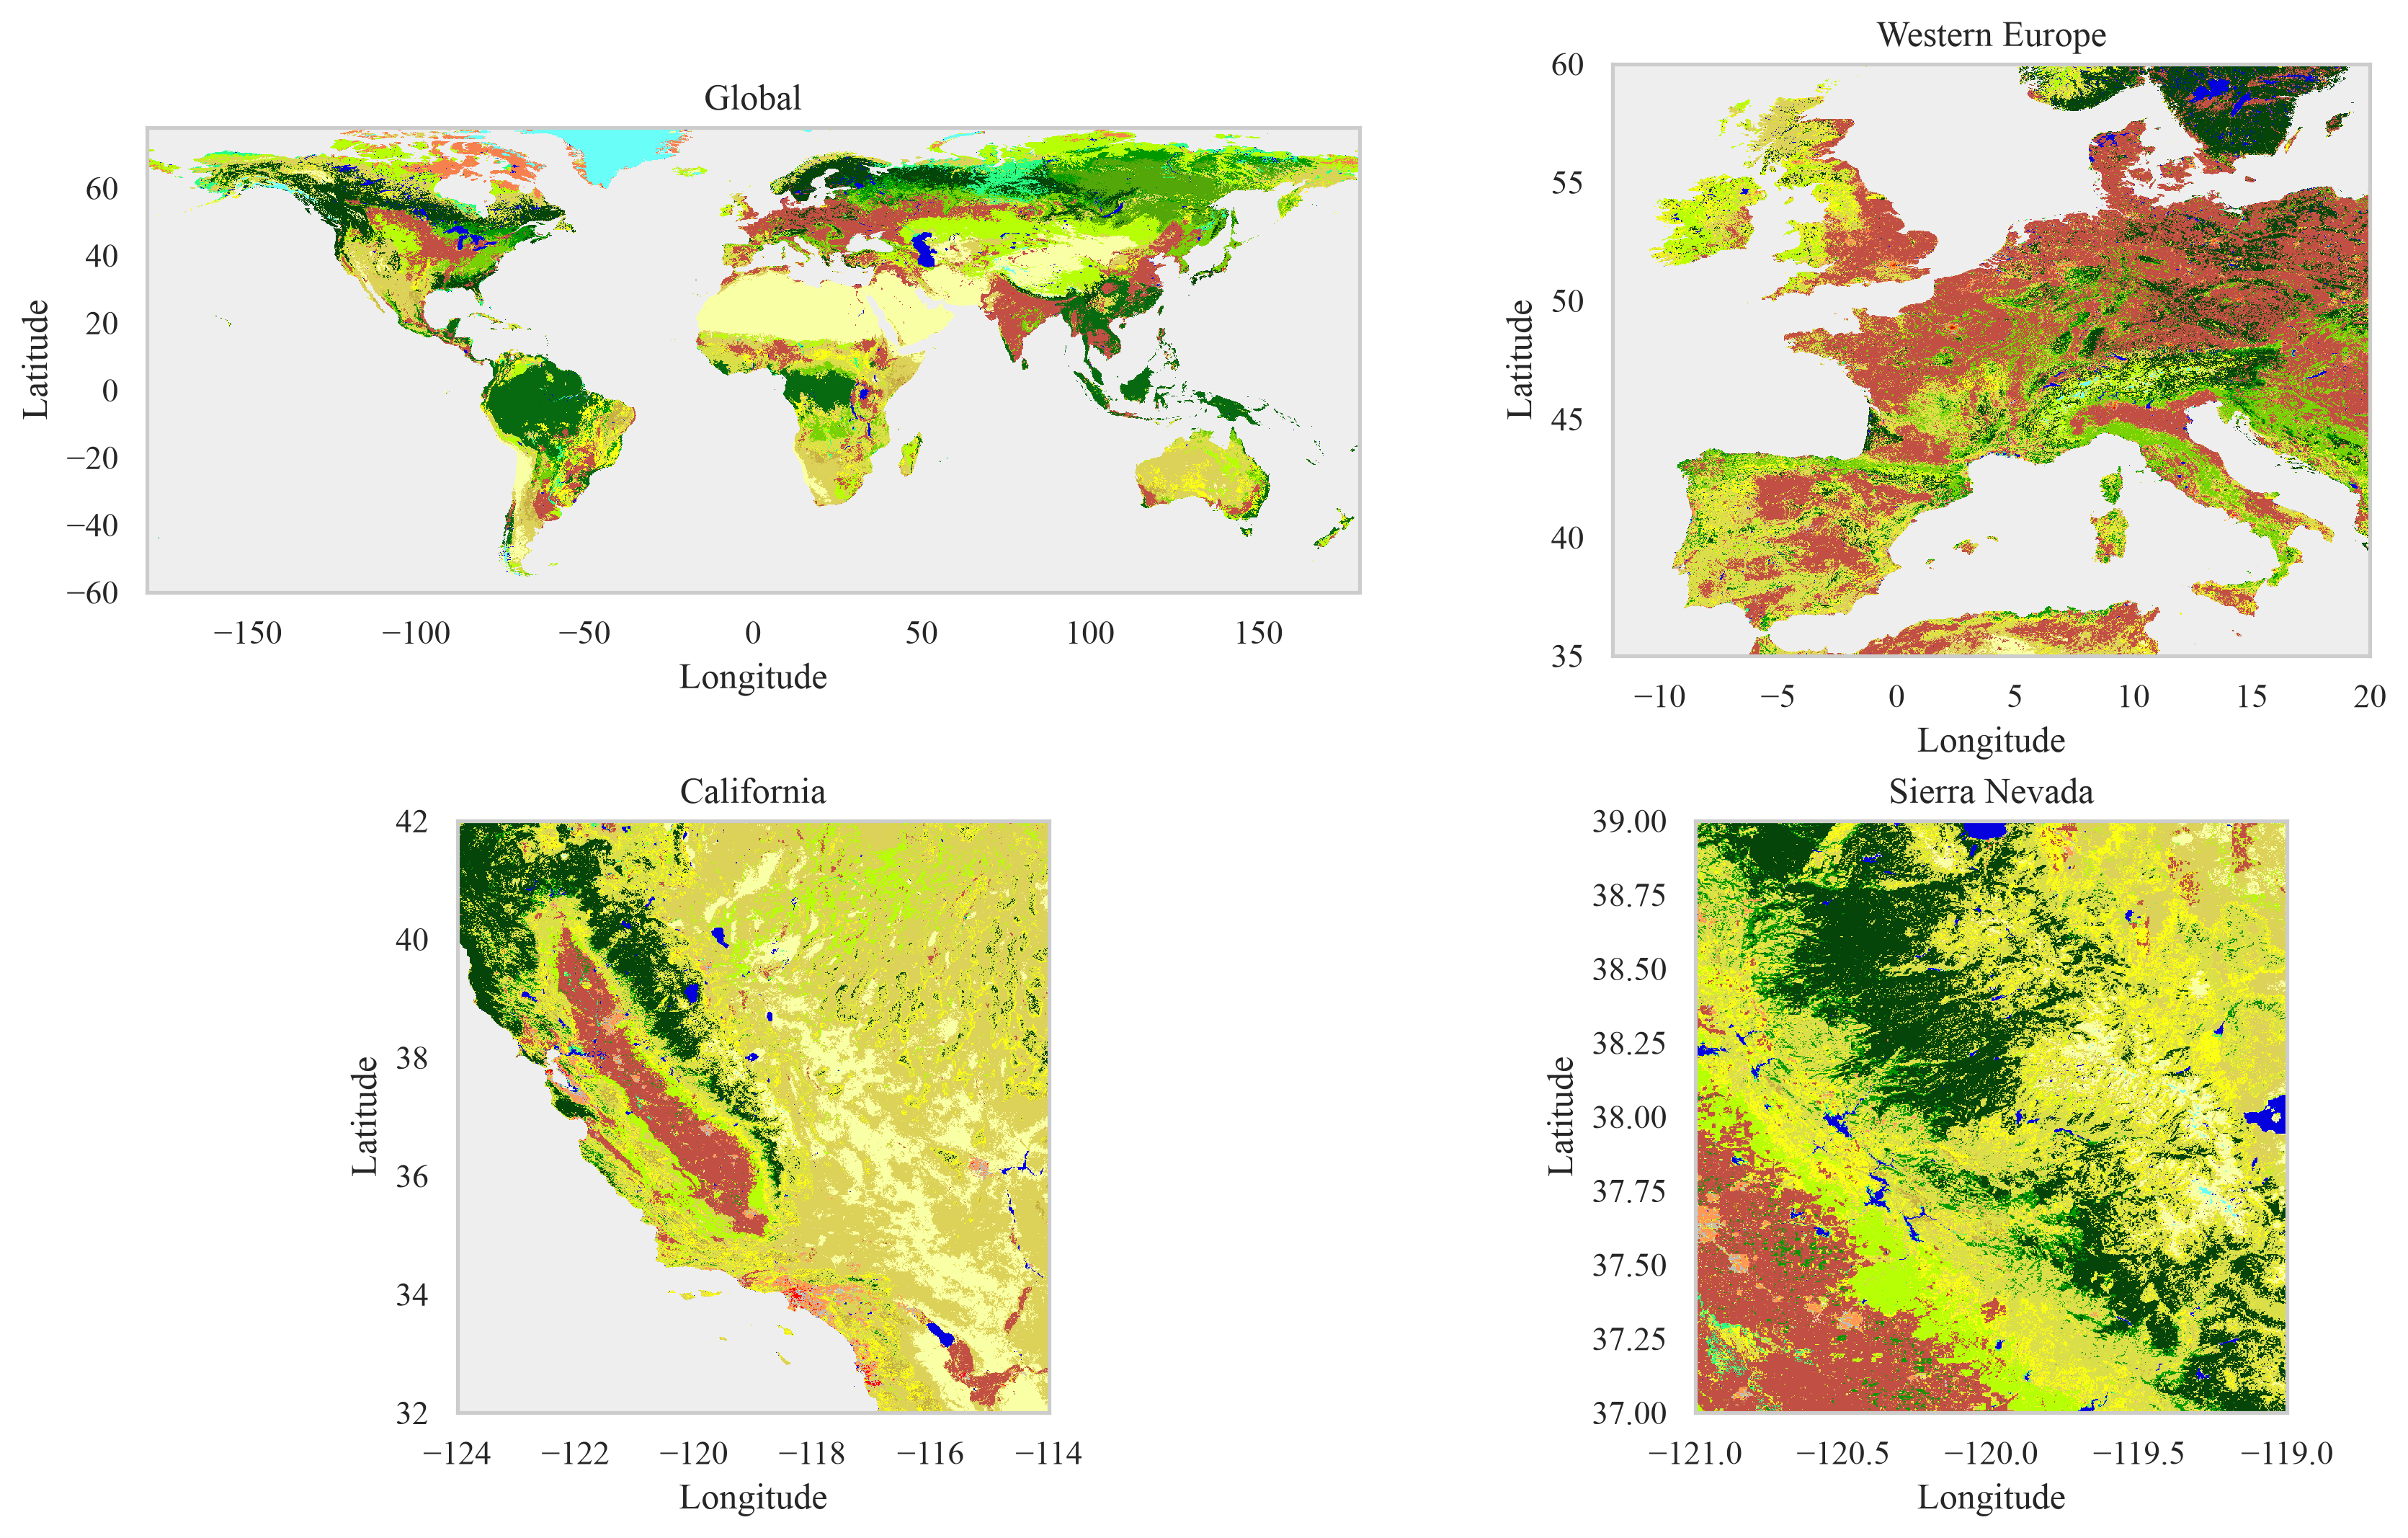

In [3]:
source = Path(
    hf_hub_download(
        repo_id="taylor-geospatial/neural-earth-fields-hackathon",
        repo_type="dataset",
        filename="CGLC-MODIS-LCZ-100m.cog.tif",
        local_dir="data",
        token=False,
    )
)
with rasterio.open(source) as src:
    width, height = src.width, src.height
    affine = src.transform
    tile_size = src.block_shapes[0][0]
    print(f"{width:,} × {height:,} pixels; {src.res}; {src.block_shapes[0]} tiles")
lookup = np.full(256, -1, dtype=np.int64)
lookup[class_codes] = np.arange(num_classes)

colors = read_palette(source, class_codes)
plot_land_cover(source, colors, output / "land_cover.png")

## Sample coordinates

Build a fixed pool across the full map, mixing random anchors and nearby pixels, then shuffle it during training. A pixel hash separates training and validation.

`train_samples` controls coverage; `nearby_fraction` and `radius_pixels` control nearby sampling. Tiles contribute equal sample counts, so sampling is not uniform over all land pixels.

In [4]:
def held_out(rows, cols):
    return (
        (rows.astype(np.int64) * 73856093) ^ (cols.astype(np.int64) * 19349663)
    ) % 5 == 0


def lonlat(rows, cols):
    return np.column_stack(
        (affine.c + (cols + 0.5) * affine.a, affine.f + (rows + 0.5) * affine.e)
    ).astype("float32")


def sample_tile(src, rng, test, nearby_fraction, count):
    while True:
        tile_row = rng.integers((height + tile_size - 1) // tile_size) * tile_size
        tile_col = rng.integers((width + tile_size - 1) // tile_size) * tile_size
        window = Window(tile_col, tile_row, tile_size, tile_size)
        labels = lookup[src.read(1, window=window)]
        tile_rows, tile_cols = np.indices(labels.shape)
        in_split = held_out(tile_rows + tile_row, tile_cols + tile_col) == test
        valid_pixels = (labels >= 0) & in_split
        candidates = np.flatnonzero(valid_pixels)
        if len(candidates):
            break

    selected_pixels = rng.choice(candidates, count)
    rows, cols = np.unravel_index(selected_pixels, labels.shape)
    nearby_count = int(count * nearby_fraction)

    if nearby_count:
        row_offsets, col_offsets = rng.integers(
            -radius_pixels, radius_pixels + 1, (2, nearby_count)
        )
        neighbor_rows = rows[:nearby_count] + row_offsets
        neighbor_cols = cols[:nearby_count] + col_offsets
        inside_tile = (
            (neighbor_rows >= 0)
            & (neighbor_rows < labels.shape[0])
            & (neighbor_cols >= 0)
            & (neighbor_cols < labels.shape[1])
        )
        neighbor_rows = neighbor_rows.clip(0, labels.shape[0] - 1)
        neighbor_cols = neighbor_cols.clip(0, labels.shape[1] - 1)
        use_neighbor = inside_tile & valid_pixels[neighbor_rows, neighbor_cols]
        rows[-nearby_count:] = np.where(
            use_neighbor, neighbor_rows, rows[:nearby_count]
        )
        cols[-nearby_count:] = np.where(
            use_neighbor, neighbor_cols, cols[:nearby_count]
        )

    coords = lonlat(rows + tile_row, cols + tile_col)
    return coords, labels[rows, cols]


def sample_pixels(count, test=False, fraction=0, seed=0):
    rng = np.random.default_rng(seed)
    coords = np.empty((count, 2), dtype="float32")
    targets = np.empty(count, dtype="int64")
    with rasterio.open(source) as src:
        for start in range(0, count, 512):
            stop = min(start + 512, count)
            coords[start:stop], targets[start:stop] = sample_tile(
                src, rng, test, fraction, stop - start
            )
    return TensorDataset(torch.from_numpy(coords), torch.from_numpy(targets))


train_data = sample_pixels(train_samples, fraction=nearby_fraction, seed=seed)
test_data = sample_pixels(test_batches * batch_size, test=True, seed=seed + 1)
train_loader = DataLoader(train_data, batch_size=batch_size, shuffle=True)
validation_loader = DataLoader(test_data, batch_size=batch_size)
print(f"{len(train_data):,} training pixels; {len(test_data):,} validation pixels")

1,048,576 training pixels; 65,536 validation pixels


## Wrap + MLP

Wrap encodes longitude and latitude as sine/cosine features and modifies its input in place. Clone coordinates you need to reuse. `model[0]` returns the middle bottleneck.

In [5]:
class Wrap(nn.Module):
    def forward(self, coords):
        coords.deg2rad_()
        features = coords.repeat_interleave(2, dim=-1)
        features[:, 0::2].cos_()
        features[:, 1::2].sin_()
        return features


encoder = nn.Sequential(
    Wrap(),
    nn.Linear(4, input_dim),
    nn.ReLU(inplace=True),
    nn.Linear(input_dim, hidden_dim),
    nn.ReLU(inplace=True),
)
decoder = nn.Sequential(nn.Linear(hidden_dim, output_dim), nn.ReLU(inplace=True))
model = nn.Sequential(encoder, decoder, nn.Linear(output_dim, num_classes)).to(device)
criterion = nn.CrossEntropyLoss()
print(model)

Sequential(
  (0): Sequential(
    (0): Wrap()
    (1): Linear(in_features=4, out_features=256, bias=True)
    (2): ReLU(inplace=True)
    (3): Linear(in_features=256, out_features=128, bias=True)
    (4): ReLU(inplace=True)
  )
  (1): Sequential(
    (0): Linear(in_features=128, out_features=256, bias=True)
    (1): ReLU(inplace=True)
  )
  (2): Linear(in_features=256, out_features=31, bias=True)
)


## Training

Train with Lightning and log TorchMetrics results. Validation uses a fixed pixel split and measures interpolation within the map. Curves below are from one run.

{'cross_entropy': 1.4137650728225708, 'accuracy': 0.518646240234375, 'macro_f1': 0.28306764364242554, 'miou': 0.20384569466114044}


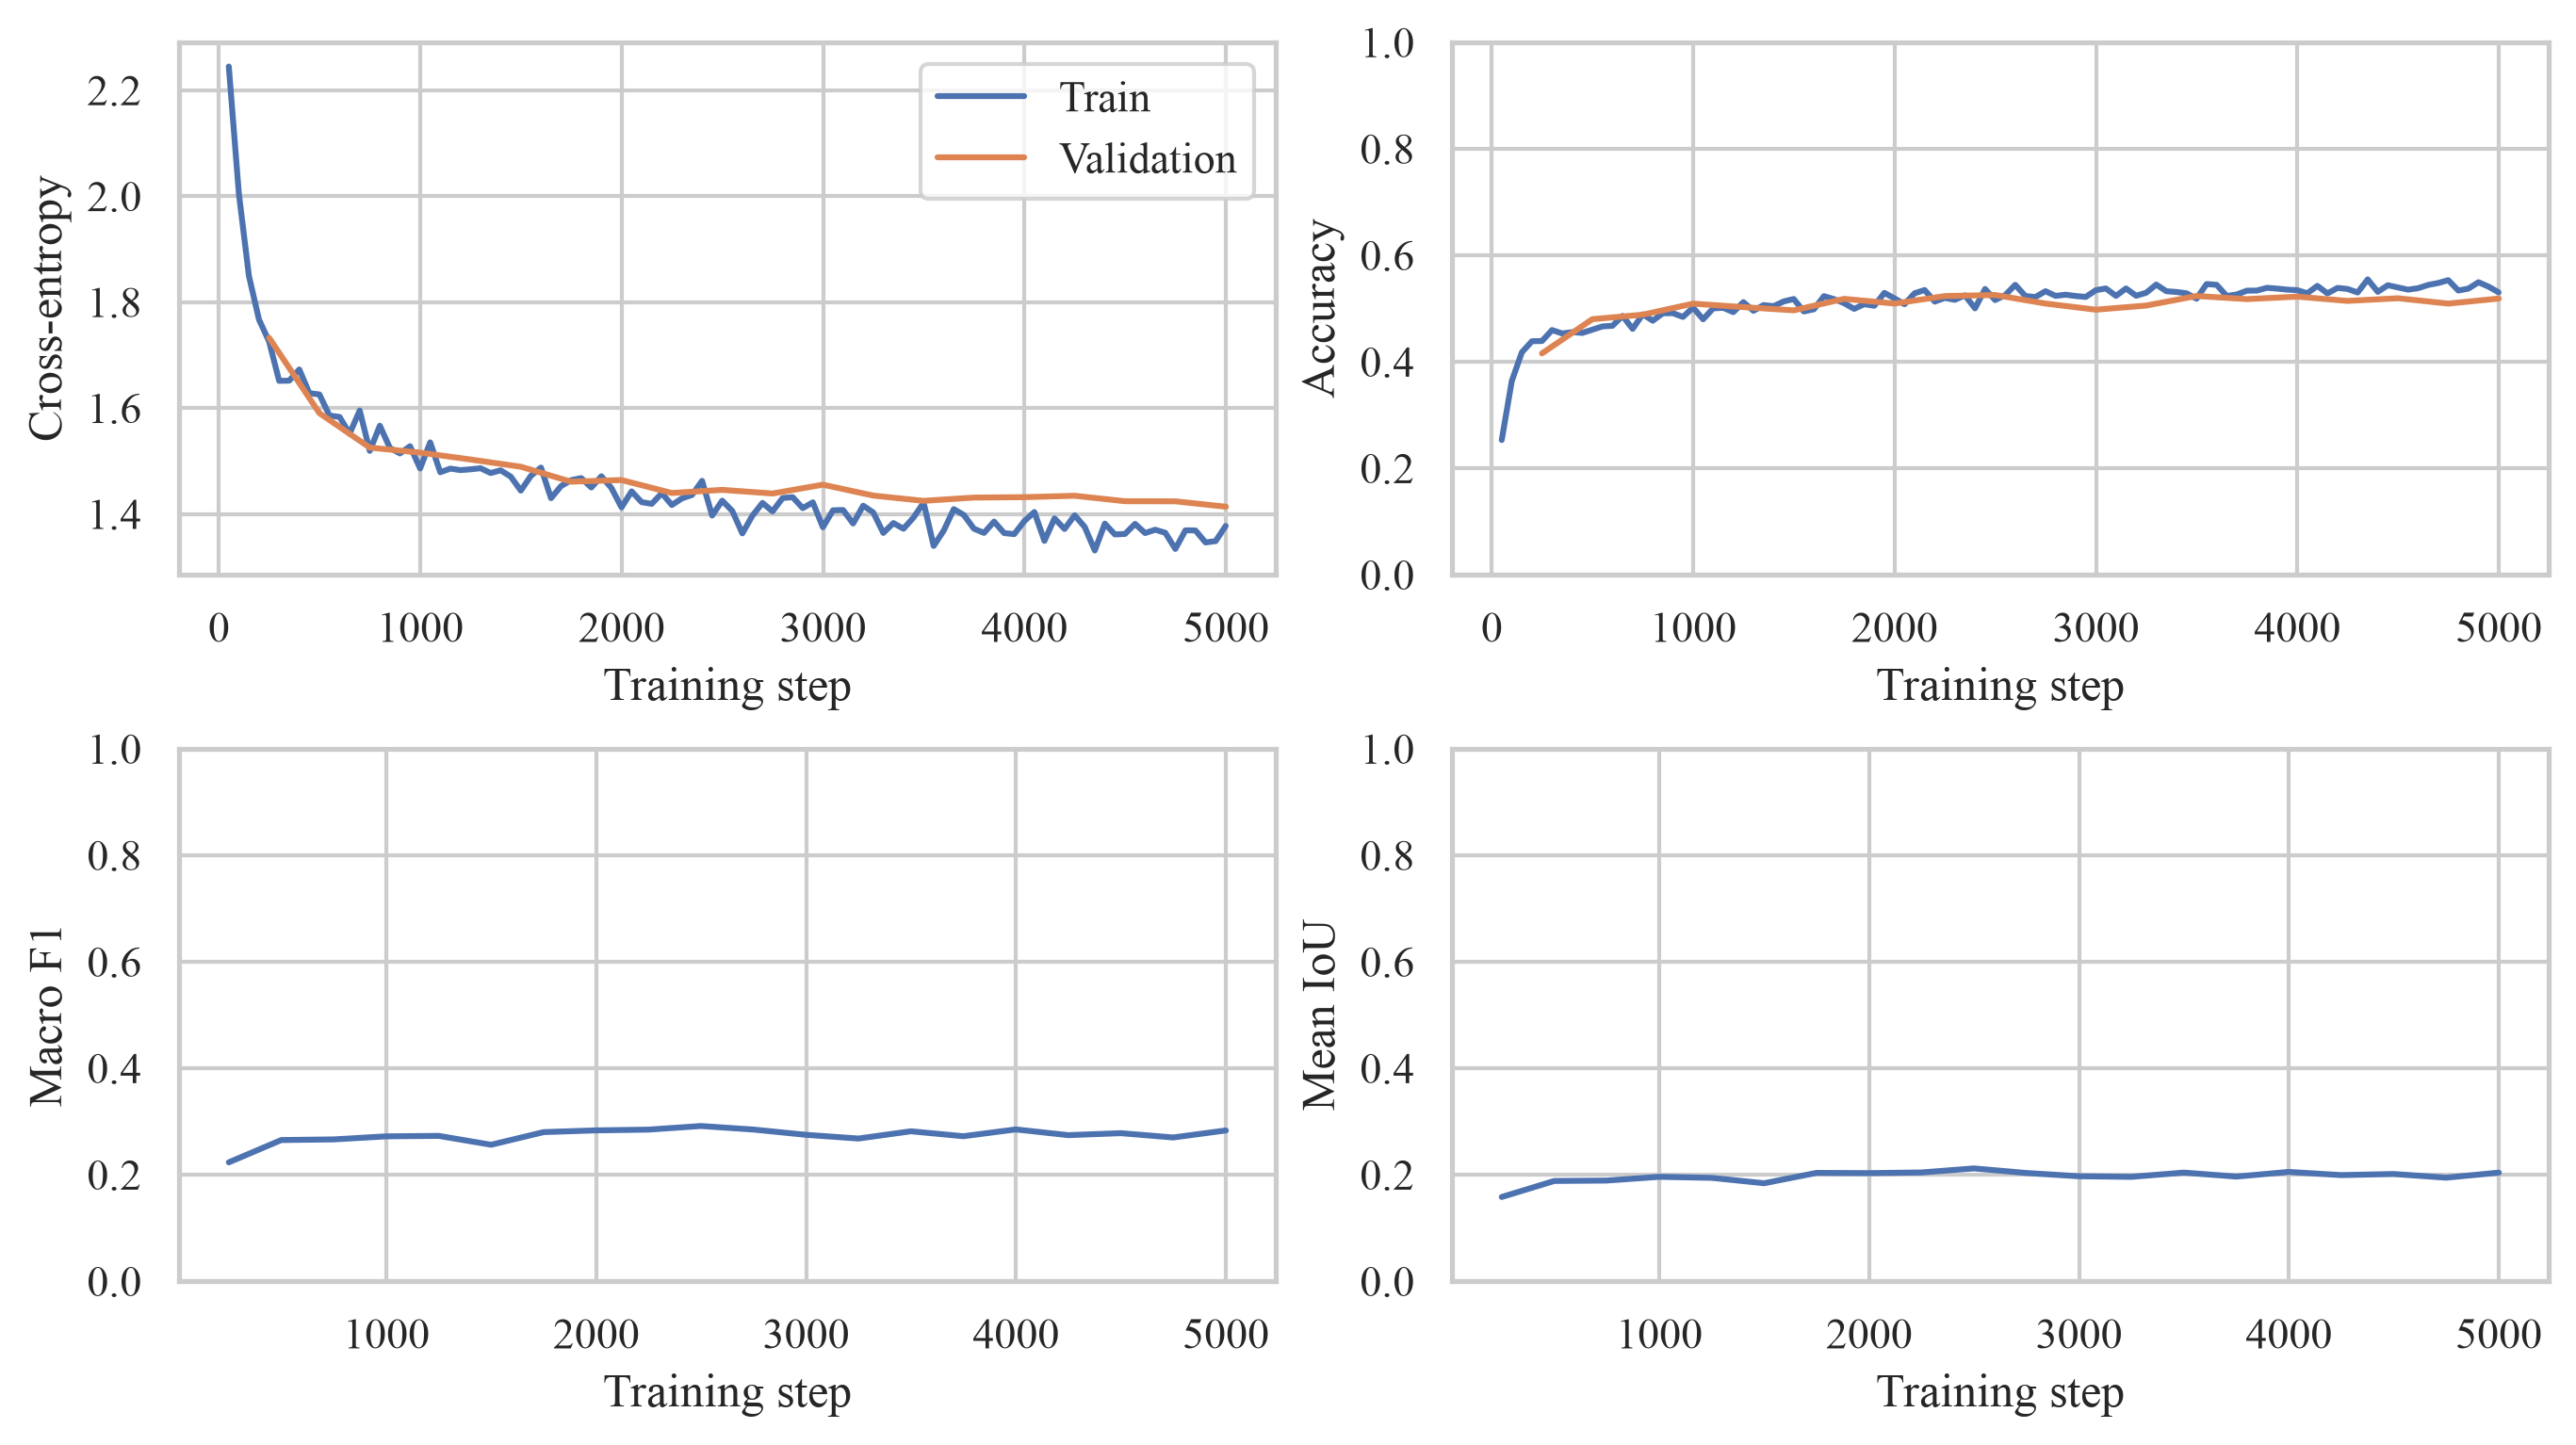

In [6]:
class LandCoverTask(L.LightningModule):
    def __init__(self, network):
        super().__init__()
        self.network = network
        self.train_accuracy = MulticlassAccuracy(
            num_classes=num_classes, average="micro"
        )
        self.validation_metrics = MetricCollection(
            {
                "accuracy": MulticlassAccuracy(
                    num_classes=num_classes, average="micro"
                ),
                "macro_f1": MulticlassF1Score(num_classes=num_classes, average="macro"),
                "miou": MulticlassJaccardIndex(
                    num_classes=num_classes, average="macro"
                ),
            }
        )

    def training_step(self, batch, batch_idx):
        coords, target = batch
        logits = self.network(coords)
        loss = criterion(logits, target)
        self.train_accuracy(logits, target)
        self.log("train_loss", loss)
        self.log("train_accuracy", self.train_accuracy, on_step=True, on_epoch=False)
        return loss

    def validation_step(self, batch, batch_idx):
        coords, target = batch
        logits = self.network(coords.clone())
        self.log("cross_entropy", criterion(logits, target), batch_size=len(target))
        self.validation_metrics.update(logits, target)
        self.log_dict(self.validation_metrics, on_step=False, on_epoch=True)

    def configure_optimizers(self):
        return torch.optim.Adam(
            (p for p in self.parameters() if p.requires_grad), lr=learning_rate
        )


def fit(network, steps, name):
    logger = CSVLogger(output, name=name)
    trainer = L.Trainer(
        accelerator=device.type,
        devices=1,
        max_steps=steps,
        val_check_interval=min(eval_every, steps),
        check_val_every_n_epoch=None,
        log_every_n_steps=min(50, steps),
        num_sanity_val_steps=0,
        enable_checkpointing=False,
        enable_progress_bar=False,
        enable_model_summary=False,
        logger=logger,
    )
    task = LandCoverTask(network)
    trainer.fit(task, train_loader, validation_loader)
    print(trainer.validate(task, validation_loader, verbose=False)[0])
    network.to(device).eval()
    return Path(logger.log_dir) / "metrics.csv"


history = fit(model, train_steps, "wrap_mlp")
plot_metrics(history, output / "wrap_mlp_metrics.png")

## Linear probe

Freeze the bottleneck and fit a fresh linear classifier directly on its embeddings.

{'cross_entropy': 1.8336453437805176, 'accuracy': 0.41278076171875, 'macro_f1': 0.20467960834503174, 'miou': 0.144862100481987}


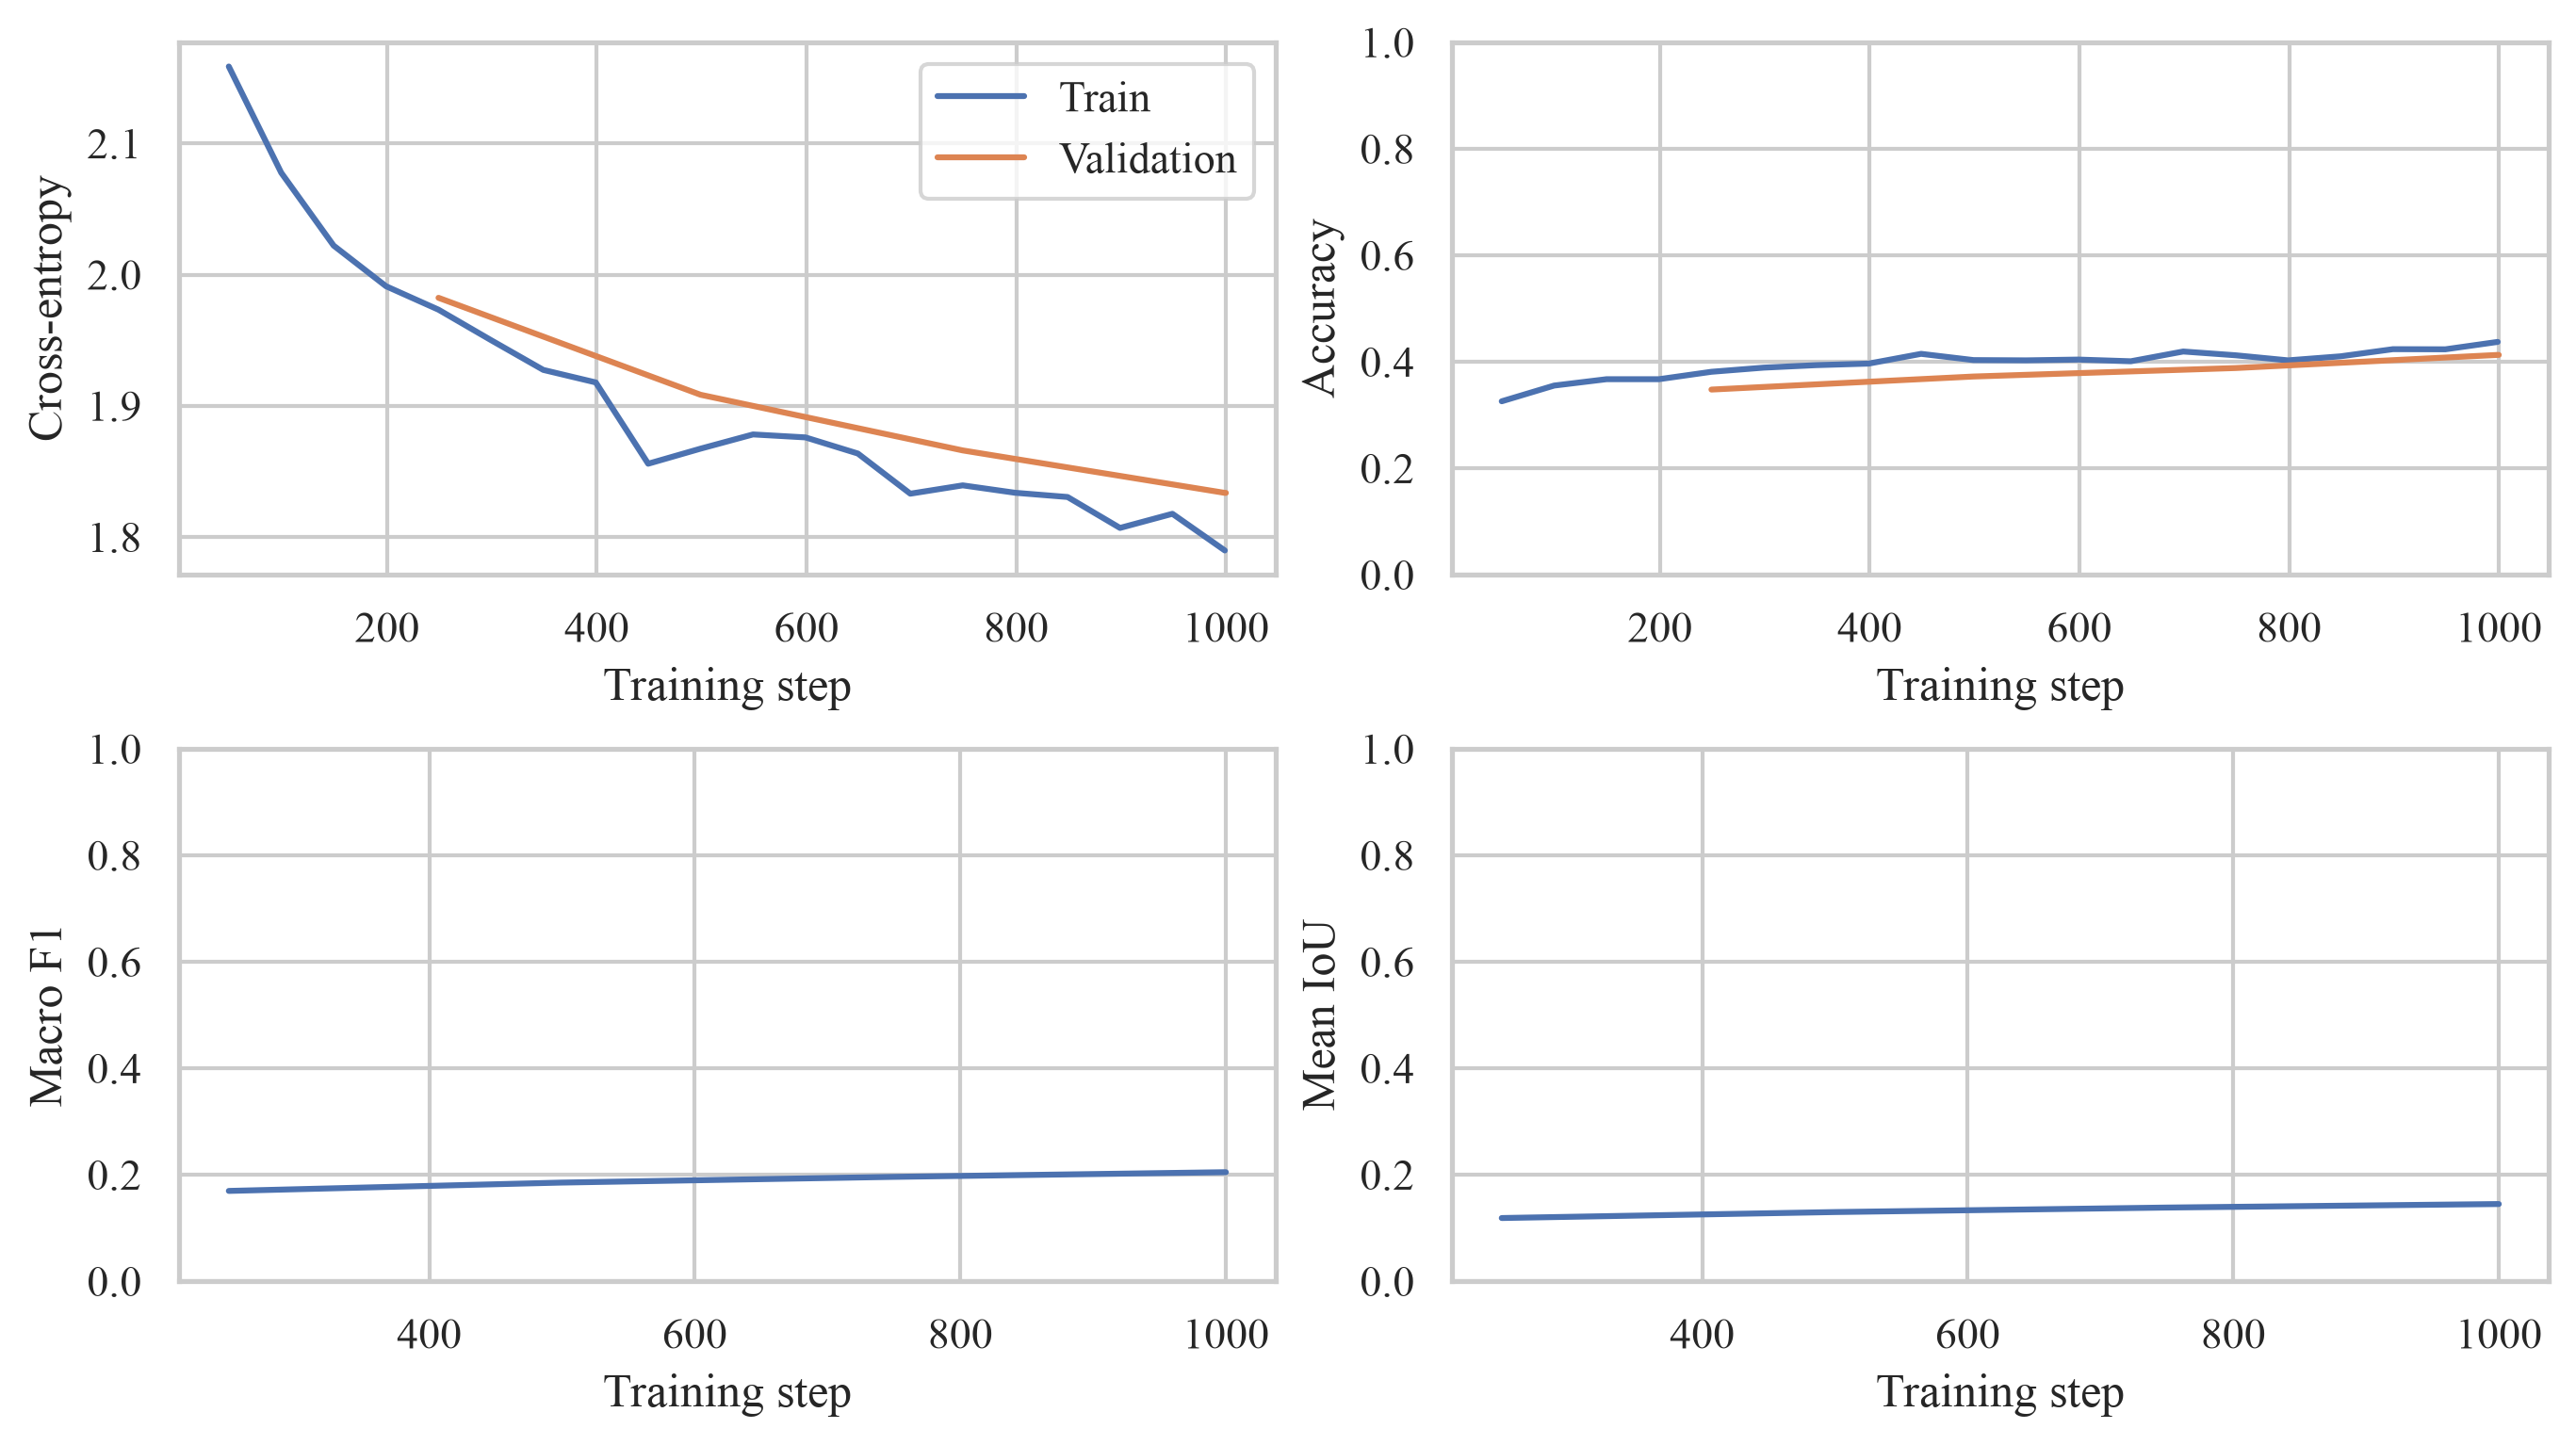

In [7]:
encoder = model[0].eval().requires_grad_(False)
linear_head = nn.Linear(hidden_dim, num_classes).to(device)
probe = nn.Sequential(encoder, linear_head)
probe_history = fit(probe, probe_steps, "linear_head")
plot_metrics(probe_history, output / "linear_head_metrics.png")


@torch.inference_mode()
def predict(network, features):
    return torch.cat(
        [
            network(part.to(device, copy=True)).cpu()
            for part in features.split(batch_size)
        ]
    )


torch.save(
    {
        "model": model.state_dict(),
        "linear_head": linear_head.state_dict(),
        "architecture": "hourglass",
        "input_dim": input_dim,
        "hidden_dim": hidden_dim,
        "output_dim": output_dim,
        "num_classes": num_classes,
        "class_codes": class_codes.tolist(),
    },
    output / "model.pt",
)

## PCA RGB

Fit PCA on sampled bottleneck embeddings and map three components to RGB, stretched to their 2nd–98th percentiles. Compare with land cover and both classifiers.

PCA explained variance: [0.341 0.285 0.211]


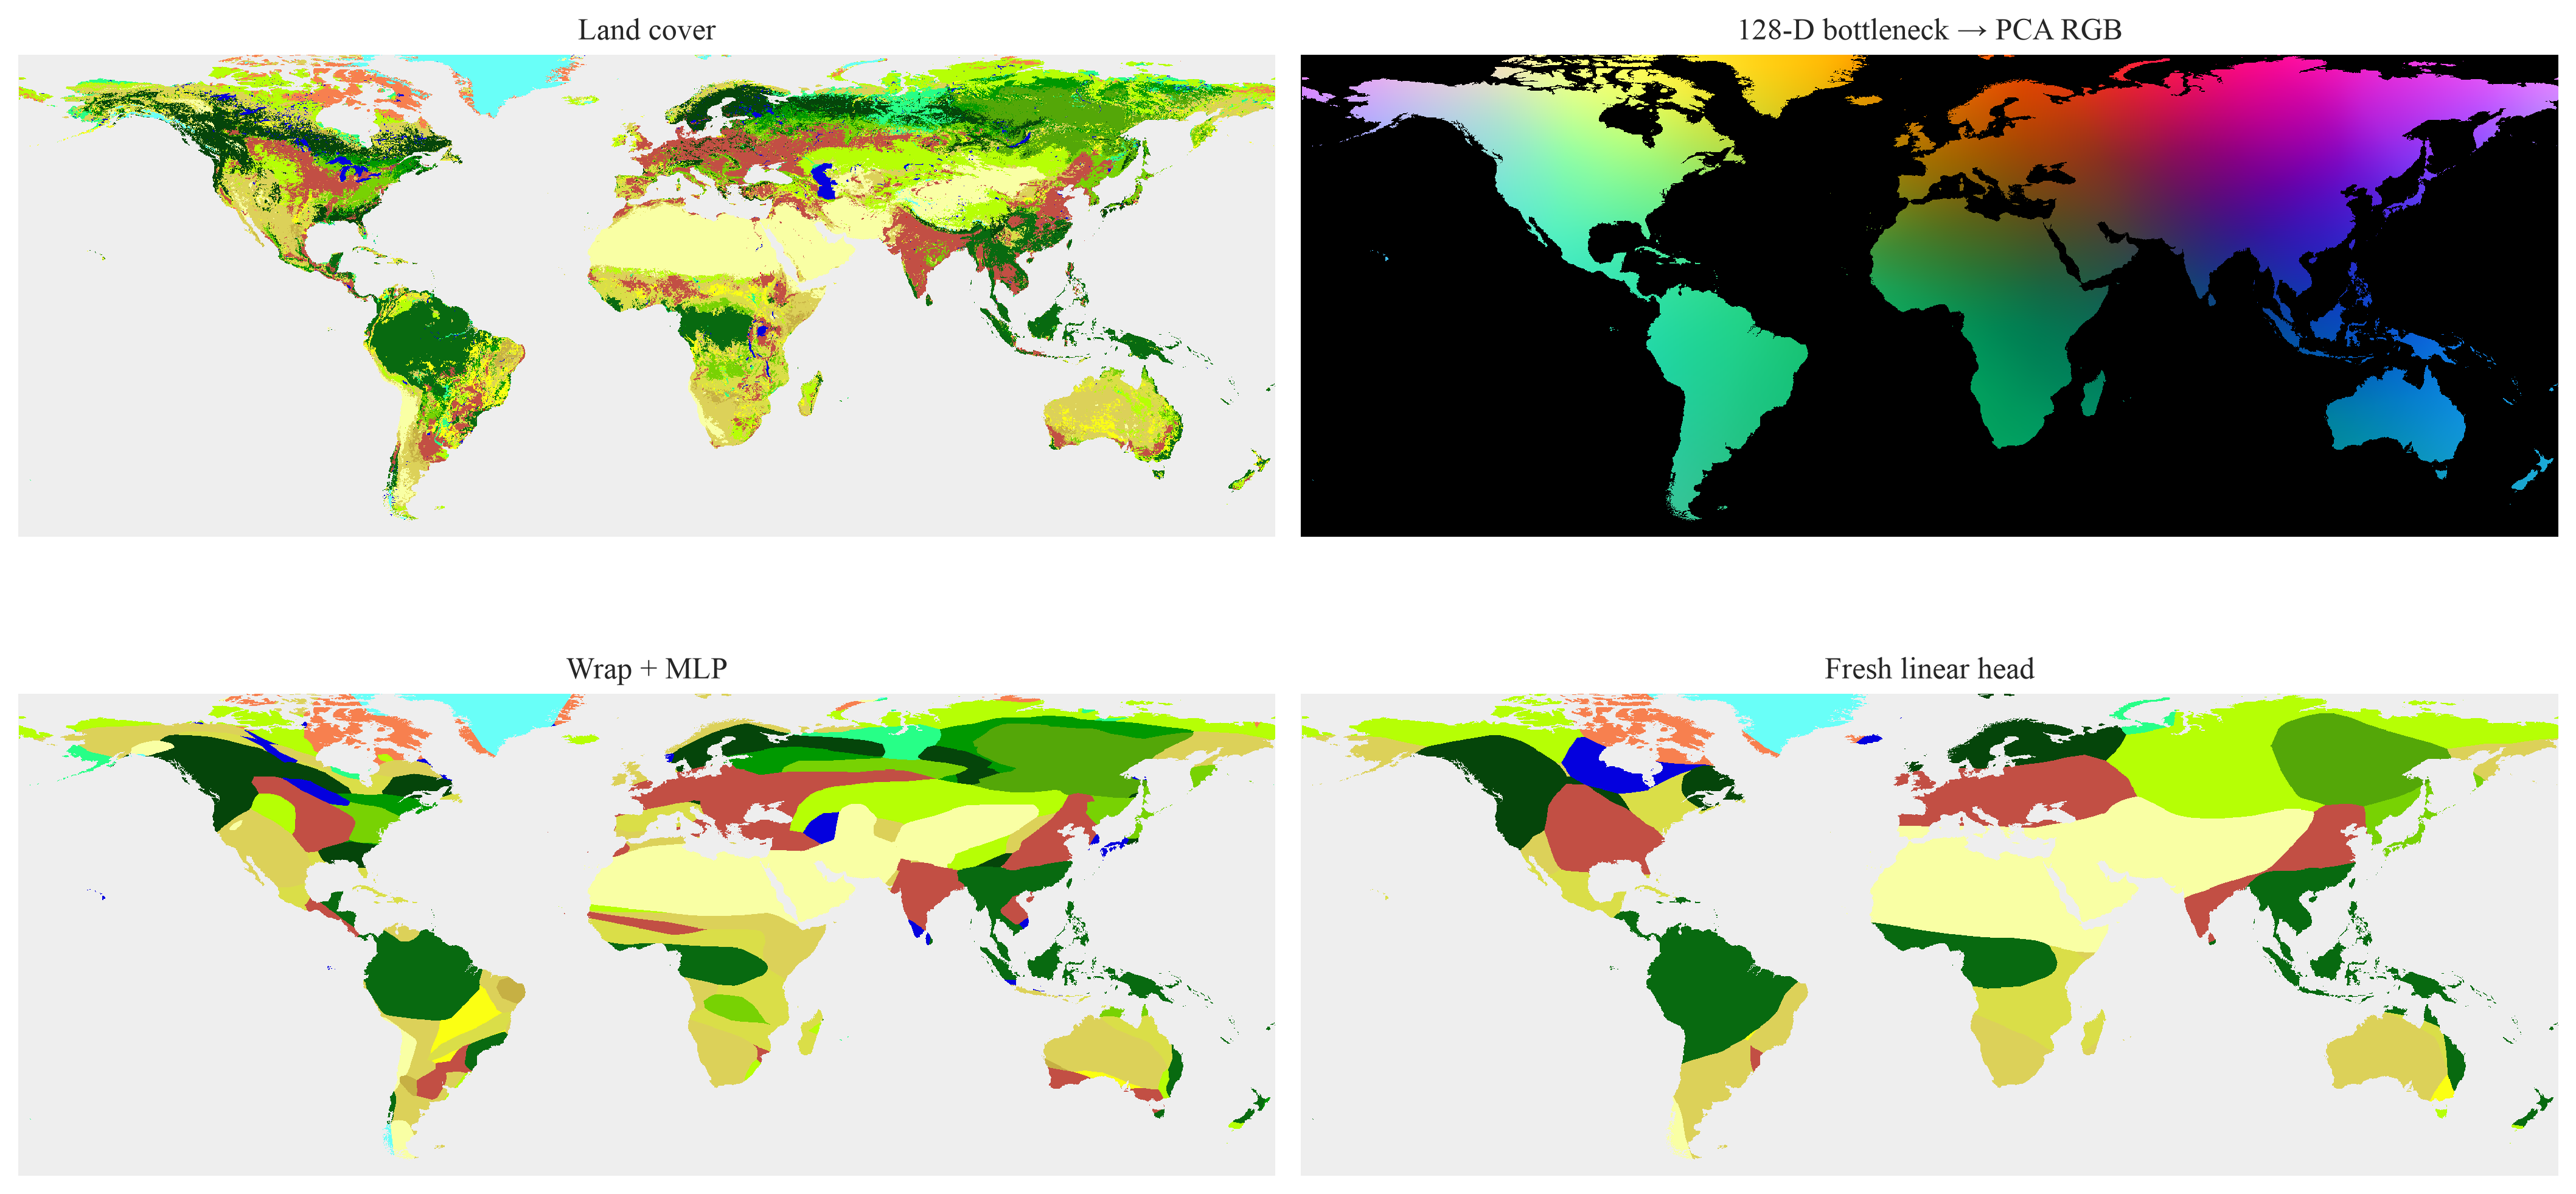

In [8]:
overview, coords = preview_grid(source, preview_height)
features = predict(encoder, torch.from_numpy(coords))
pca_features = predict(encoder, train_data.tensors[0][:65536])
rgb = pca_rgb(pca_features.numpy(), features.numpy(), overview.shape, seed)
predictions = {
    name: predict(head, features).argmax(1).numpy().reshape(overview.shape)
    for name, head in [("Wrap + MLP", model[1:]), ("Fresh linear head", linear_head)]
}
plot_comparison(
    lookup[overview],
    predictions,
    rgb,
    colors,
    class_codes,
    hidden_dim,
    output / "global_comparison.png",
)

## Export rasters

Use [inference.ipynb](inference.ipynb) to export embedding and prediction COGs.

Dataset by Demuzere, He, Martilli, and Zonato (2023), [CC BY 4.0](https://doi.org/10.5281/zenodo.7670653).